In [165]:
import pandas as pd

# Carregar o dataset
df = pd.read_csv('googleplaystore.csv')

# Exibir as primeiras linhas do dataset
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [167]:
# Remover as linhas duplicadas
df = df.drop_duplicates(subset=['App'])

# Verificar as primeiras linhas após a remoção
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


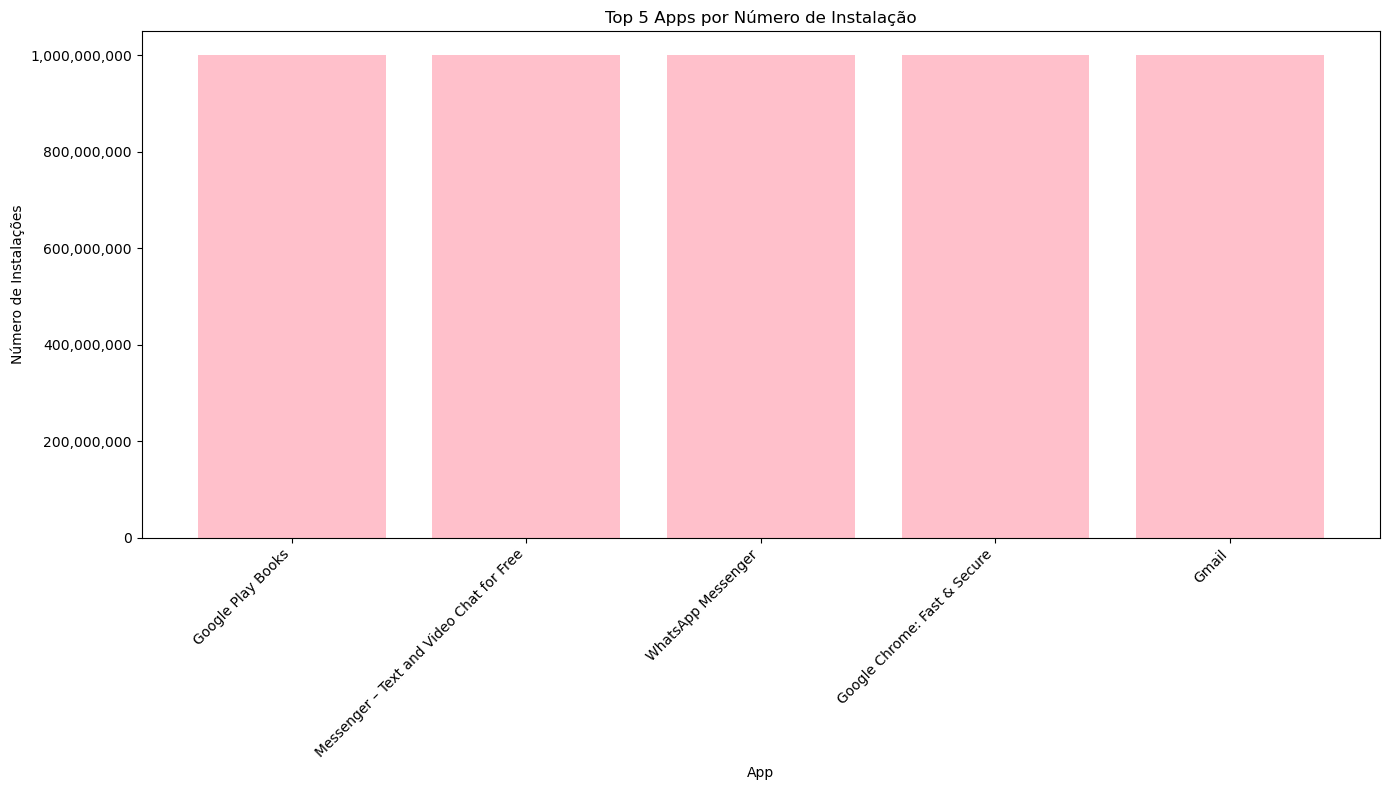

In [146]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

# Função para limpar a coluna 'Installs'
def clean_installs_column(df: pd.DataFrame, column_name: str = 'Installs') -> pd.DataFrame:
    
    # Copia o DataFrame para não alterar o original
    df_copy = df.copy()
    
    # Remove caracteres não numéricos (como '+' e ',')
    df_copy[column_name] = df_copy[column_name].str.replace(r'[^\d]', '', regex=True)
    
    # Substitui valores vazios por 0
    df_copy[column_name] = df_copy[column_name].replace('', '0')
    
    # Converte a coluna para tipo inteiro
    df_copy[column_name] = df_copy[column_name].astype(int)
    
    return df_copy

# Função para plotar os top N aplicativos por número de instalações
def plot_top_apps_by_installs(df: pd.DataFrame, 
                             n: int = 5, 
                             app_col: str = 'App', 
                             installs_col: str = 'Installs',
                             figsize: tuple = (14, 8),
                             color: str = 'pink') -> None:
    
    # Seleciona os N aplicativos com maior número de instalações
    top_n_apps = df.nlargest(n, installs_col)
    
    # Cria o gráfico
    plt.figure(figsize=figsize)  # Define o tamanho da figura
    plt.bar(top_n_apps[app_col], top_n_apps[installs_col], color=color)  # Plota as barras
    plt.title(f'Top {n} Apps por Número de Instalação')  # Título do gráfico
    plt.xlabel('App')  # Rótulo do eixo X (nomes dos aplicativos)
    plt.ylabel('Número de Instalações')  # Rótulo do eixo Y (número de instalações)
    
    # Formatação do eixo Y para evitar notação científica e mostrar números inteiros
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    
    # Rotaciona os rótulos no eixo X para facilitar a leitura
    plt.xticks(rotation=45, ha="right")
    
    # Ajusta o layout do gráfico para evitar que algo seja cortado
    plt.tight_layout()
    
    # Exibe o gráfico
    plt.show()

# Limpeza da coluna 'Installs' e criação do gráfico
df = clean_installs_column(df)  # Limpa a coluna 'Installs'
plot_top_apps_by_installs(df)  # Plota o gráfico com os 5 apps mais instalados


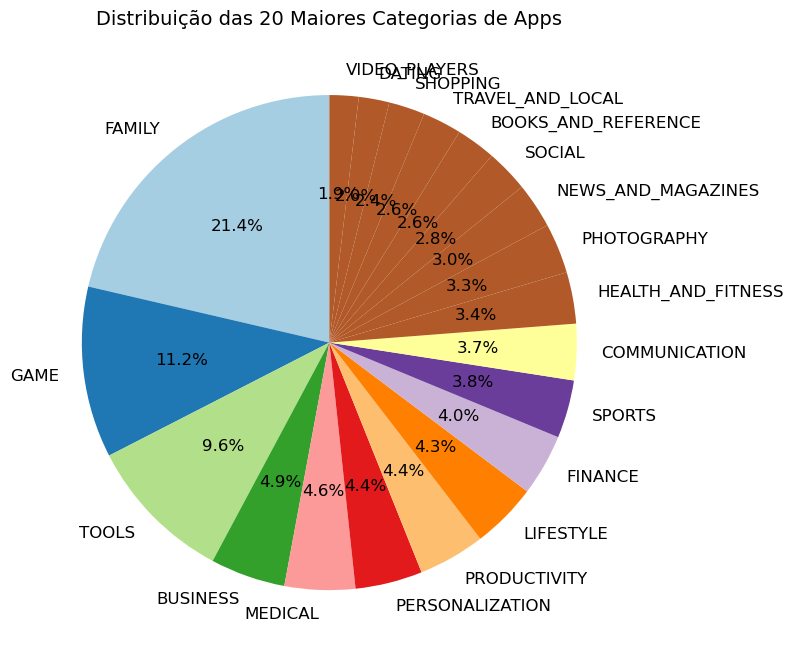

In [168]:
import matplotlib.pyplot as plt
import pandas as pd

# Contar a frequência das categorias
category_counts = df['Category'].value_counts()

# Selecionar as 20 maiores categorias
top_20_categories = category_counts.head(20)

# Definir cores personalizadas para o gráfico 
colors = plt.cm.Paired(range(len(top_20_categories)))

# Plotar o gráfico de pizza
plt.figure(figsize=(8, 8)) 

top_20_categories.plot.pie(
    autopct='%1.1f%%',  # Exibir a porcentagem com uma casa decimal
    startangle=90,  # Iniciar o gráfico em um ângulo diferente
    textprops={'fontsize': 12},  # Aumenta o tamanho da fonte dos rótulos
    colors=colors,  # Definindo as cores
    labels=top_20_categories.index,  # Garante que todas as categorias apareçam corretamente
)

# Definir o título do gráfico
plt.title('Distribuição das 20 Maiores Categorias de Apps', fontsize=14)

# Remover o rótulo 'ylabel' que é desnecessário
plt.ylabel('')

# Ajustar o layout para evitar sobreposição
plt.tight_layout()

# Exibir o gráfico
plt.show()

In [148]:
# Converter a coluna 'Price' para numérica, removendo o símbolo de moeda
df['Price'] = pd.to_numeric(df['Price'].replace('[$,]', '', regex=True), errors='coerce')

df = df.dropna(subset=['Price']) 

# Encontrar o app mais caro
most_expensive_app = df.loc[df['Price'].idxmax()]

print(f'O app mais caro é: {most_expensive_app["App"]}, com o preço de {most_expensive_app["Price"]}')

O app mais caro é: I'm Rich - Trump Edition, com o preço de 400.0


In [149]:
# Contar o número de apps com a classificação 'Mature 17+'
mature_apps = df[df['Content Rating'] == 'Mature 17+']
print(f'Número de apps com classificação "Mature 17+": {mature_apps.shape[0]}')


Número de apps com classificação "Mature 17+": 393


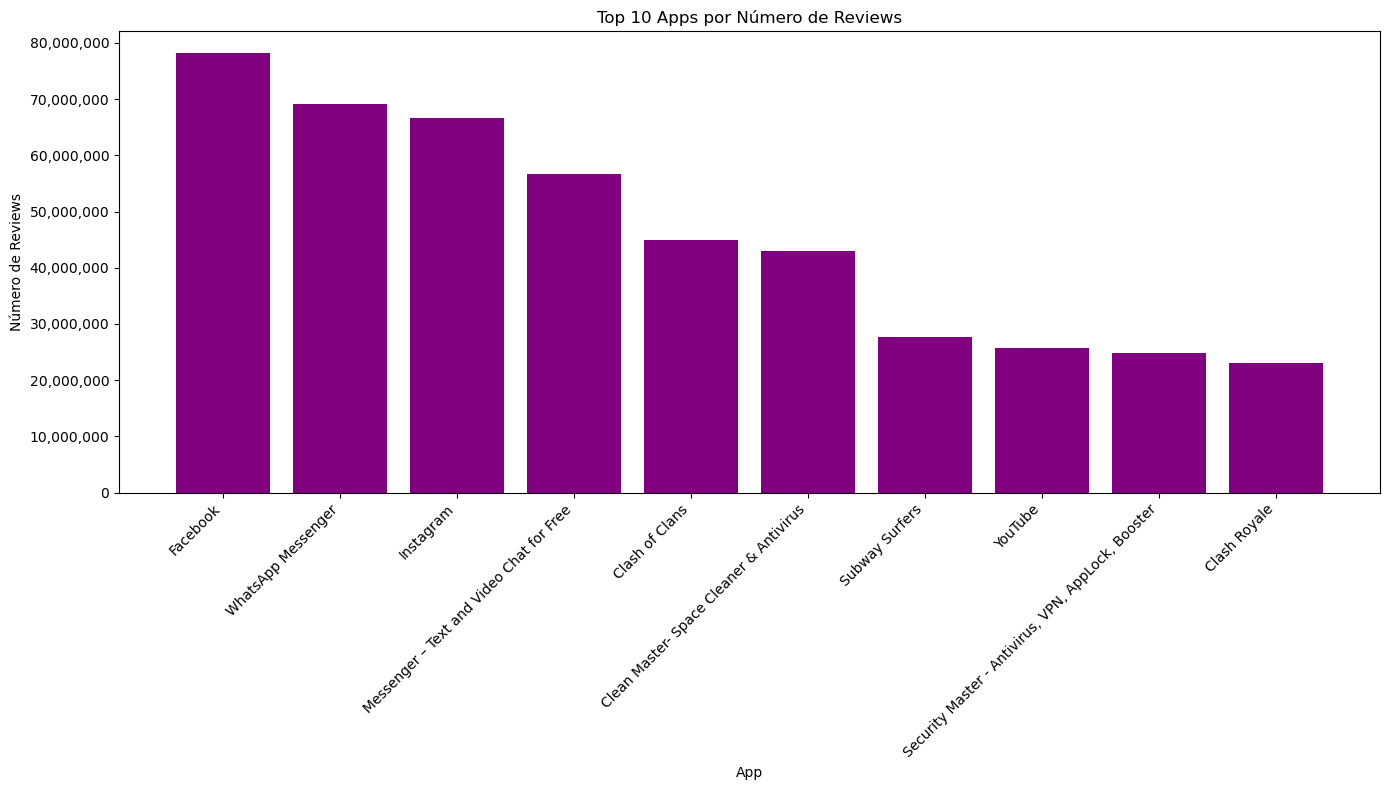

In [150]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

# Função para limpar a coluna 'Reviews'
def clean_reviews_column(df: pd.DataFrame, column_name: str = 'Reviews') -> pd.DataFrame:
    # Copia o DataFrame para não alterar o original
    df_copy = df.copy()
    
    # Converte para valores numéricos, forçando erro em valores não numéricos (transformando-os em NaN)
    df_copy[column_name] = pd.to_numeric(df_copy[column_name], errors='coerce')
    
    # Substitui valores NaN por 0
    df_copy[column_name] = df_copy[column_name].fillna(0).astype(int)
    
    return df_copy

# Função para plotar os top N aplicativos por número de reviews
def plot_top_apps_by_reviews(df: pd.DataFrame, 
                             n: int = 10, 
                             app_col: str = 'App', 
                             reviews_col: str = 'Reviews',
                             figsize: tuple = (14, 8),
                             color: str = 'purple') -> None:
    
    # Seleciona os N aplicativos com maior número de reviews
    top_n_apps = df.nlargest(n, reviews_col)
    
    # Cria o gráfico
    plt.figure(figsize=figsize)  # Define o tamanho da figura
    plt.bar(top_n_apps[app_col], top_n_apps[reviews_col], color=color)  # Plota as barras
    plt.title(f'Top {n} Apps por Número de Reviews')  # Título do gráfico
    plt.xlabel('App')  # Rótulo do eixo X (nomes dos aplicativos)
    plt.ylabel('Número de Reviews')  # Rótulo do eixo Y (número de reviews)
    
    # Formatação do eixo Y para evitar notação científica e mostrar números inteiros
    plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    
    # Rotaciona os rótulos no eixo X para facilitar a leitura
    plt.xticks(rotation=45, ha="right")
    
    # Ajusta o layout do gráfico para evitar que algo seja cortado
    plt.tight_layout()
    
    # Exibe o gráfico
    plt.show()

# Limpeza da coluna 'Reviews' e criação do gráfico
df = clean_reviews_column(df)  # Limpa a coluna 'Reviews'
plot_top_apps_by_reviews(df)  # Plota o gráfico com os 10 apps com mais reviews


In [156]:
import matplotlib.pyplot as plt
import pandas as pd

# Remover linhas duplicadas
df = df.drop_duplicates()

# 1. Cálculo em formato de lista: Top 3 apps com mais reviews
top_reviews = df.sort_values(by='Reviews', ascending=False).head(5)
print("Top 5 apps por número de reviews:")
print(top_reviews[['App', 'Reviews']])

# 2. Cálculo em formato de valor: Preço médio dos apps
mean_price = df['Price'].mean()
print(f'\nPreço médio dos apps: {mean_price}')

Top 5 apps por número de reviews:
                                           App   Reviews
2544                                  Facebook  78158306
336                         WhatsApp Messenger  69119316
2545                                 Instagram  66577313
335   Messenger – Text and Video Chat for Free  56642847
1670                            Clash of Clans  44891723

Preço médio dos apps: 1.0992990992856404


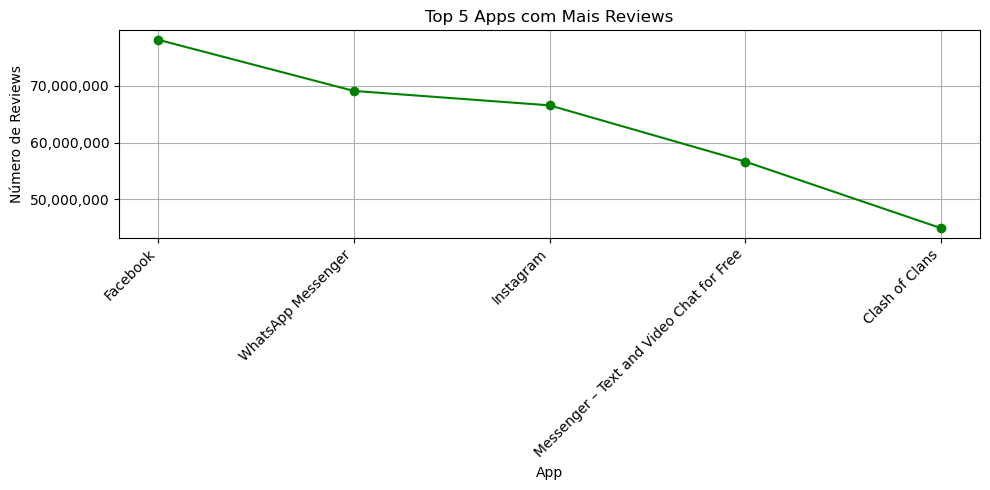

In [152]:
from matplotlib.ticker import StrMethodFormatter

plt.figure(figsize=(10, 5))
plt.plot(top_reviews['App'], top_reviews['Reviews'], marker='o', linestyle='-', color='green')
plt.title('Top 5 Apps com Mais Reviews')
plt.xlabel('App')
plt.ylabel('Número de Reviews')
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.grid(True)
plt.show()

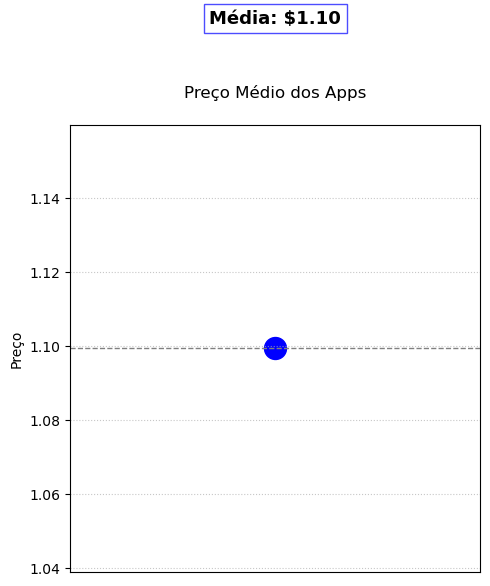

In [155]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 6))  # Tamanho mais proporcional
plt.scatter(0.5, mean_price, color='blue', s=250, label='Média')  # Centraliza no eixo x

# Linha horizontal indicando a média
plt.axhline(mean_price, color='gray', linestyle='--', linewidth=1)

# Texto destacado acima do ponto
plt.text(0.5, mean_price + mean_price * 0.08, 
         f'Média: ${mean_price:.2f}', 
         ha='center', fontsize=13, fontweight='bold',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='blue'))

plt.xlim(0, 1)
plt.xticks([])
plt.ylabel('Preço')
plt.title('Preço Médio dos Apps', pad=20)
plt.grid(True, axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()